# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\FunctionsInferenceScallable.jl")

CompRepUtil_Entro_OEDmc2 (generic function with 1 method)

# Define Priors

In [3]:
priorTheta, priotY0, sampsTh, sampsY0 = genPriorSamps(8000);
bounds, boundY0 = genThetaBounds();


In [4]:
priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try2.csv", DataFrame))

8000×17 Matrix{Float64}:
 57.7608  51.23  8.83467e-5   0.0215784  …  235.849   1979.81  1.12283
 59.9265  51.23  7.69803e-5   0.0235835     674.49    1745.15  1.3331
 60.3396  51.23  0.000110566  0.0219877     351.782   1630.03  1.20839
 58.0129  51.23  6.28828e-5   0.0224365     123.707   5437.7   1.07724
 56.4488  51.23  6.67446e-5   0.0202043      74.8948  1292.51  0.993744
 57.1069  51.23  6.34323e-5   0.0217551  …   62.5183  1634.41  1.02064
 58.2983  51.23  5.67167e-5   0.0237257      56.0641  2890.22  1.05647
 54.9611  51.23  8.91107e-5   0.0204267     642.228   3348.77  1.16344
 55.9022  51.23  6.26698e-5   0.0224771     508.422   3221.74  1.15968
 55.048   51.23  7.23989e-5   0.0210584     441.643   1349.33  1.09763
  ⋮                                      ⋱               ⋮     
 54.8584  51.23  6.24267e-5   0.0208047     851.049   4779.53  1.04301
 51.3692  51.23  6.49116e-5   0.0187943     141.481   2001.06  0.914754
 52.1235  51.23  6.61308e-5   0.0186466     142.224   2286

# Compute Objective Function for All Available Experiments

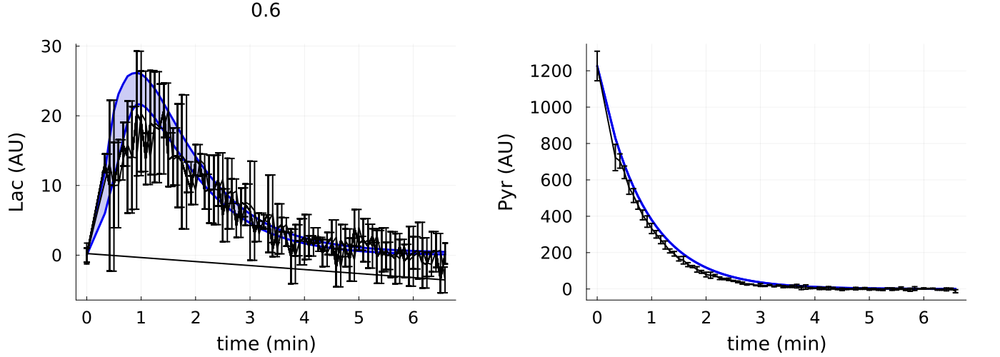

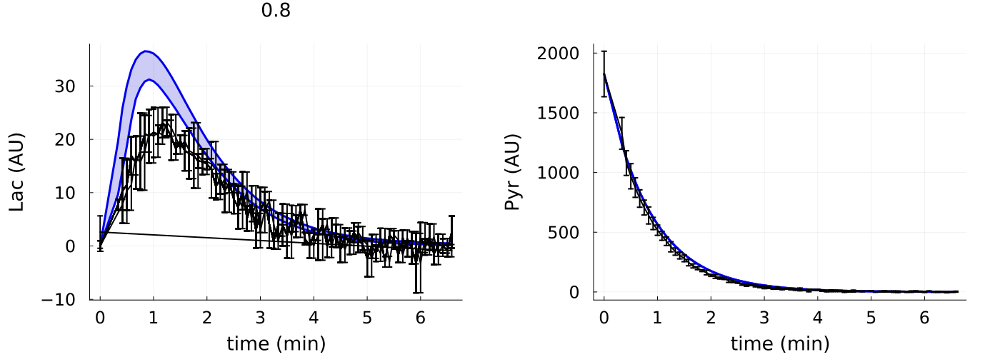

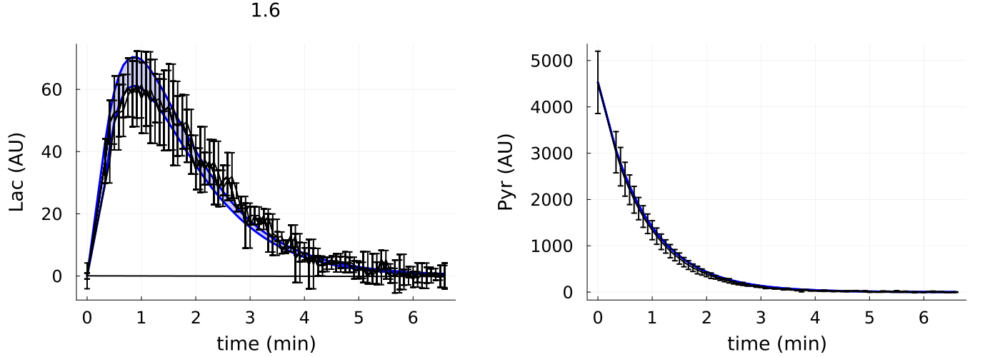

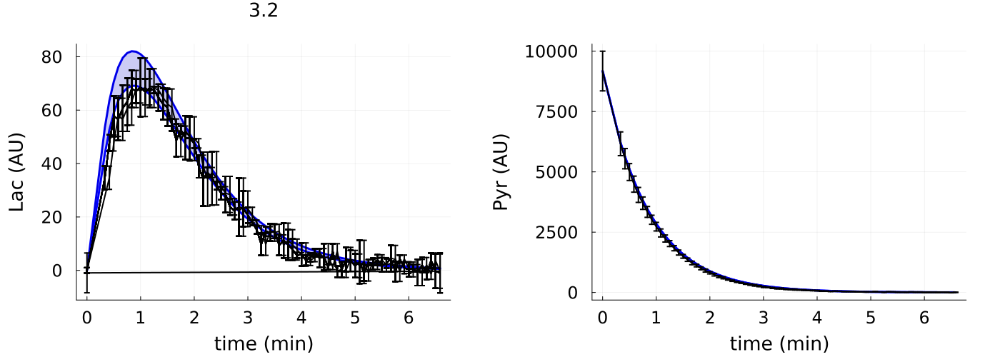

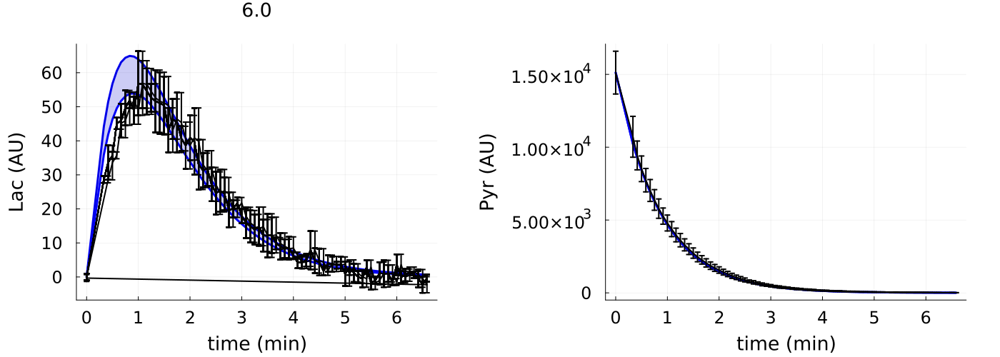

...

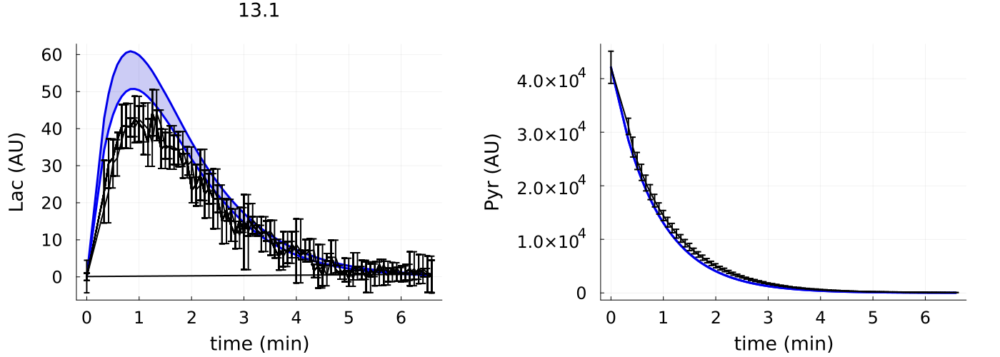

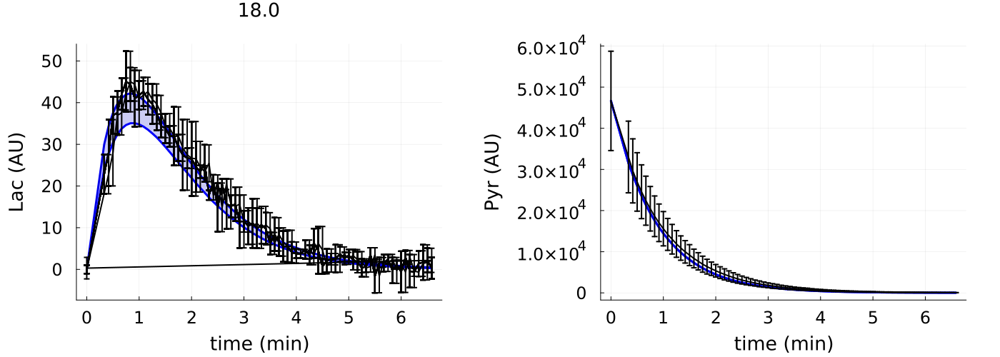

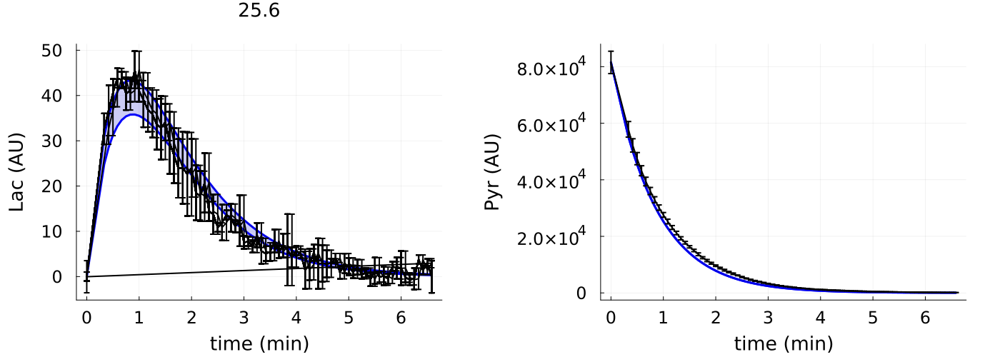

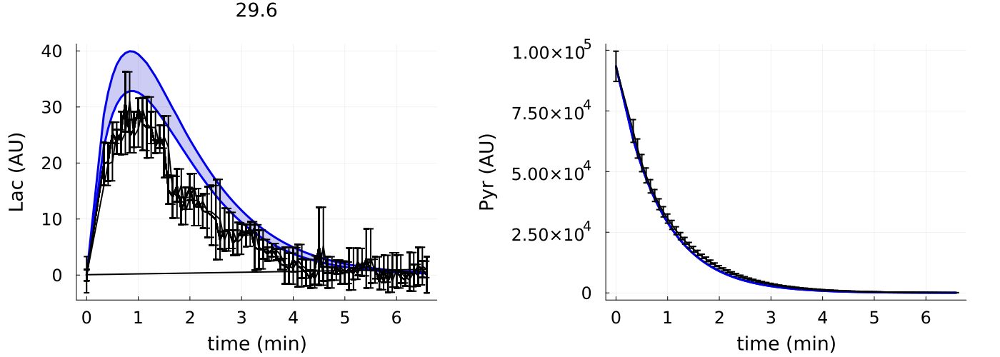

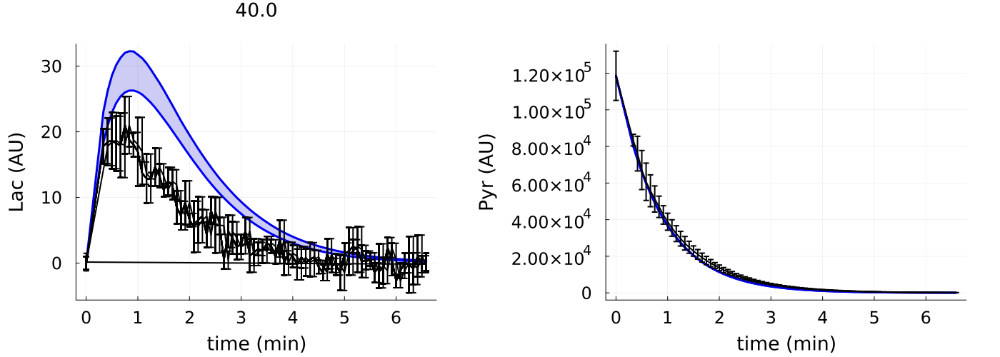

In [5]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths2 = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_0-8mMPyr_Dat.csv", mainpath*"3Mil_1-6mMPyr_Dat.csv", mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_6-0mMPyr_Dat.csv", 
          mainpath*"3Mil_6-4mMPyr_Dat.csv", mainpath*"3Mil_8-3mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv", mainpath*"3Mil_13-1mMPyr_Dat.csv", mainpath*"3Mil_18-0mMPyr_Dat.csv", 
          mainpath*"3Mil_25-6mMPyr_Dat.csv", mainpath*"3Mil_29-6mMPyr_Dat.csv", mainpath*"3Mil_40-0mMPyr_Dat.csv", ];
conce2 = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29.6, 40];


Random.seed!(8987654);
global datAll = restructDatInfCompRep_RealExpDat_Scal(paths2, conce2, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])




simPriorPredictAll(2000, datAll, priorInfer[:,1:14], priorInfer[:,15:end], conce2)

In [6]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:14];
global sampsY0 = priorInfer[:,15:end];

pyrs = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40]
# pyrs = [0.6, 0.8, 1.6, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40] # At each iteration we remove past experiments

objs = zeros(length(pyrs))

for i in 1:length(pyrs)
    objs[i] = CompRepUtil_Entro_OEDmc2([pyrs[i]])
end

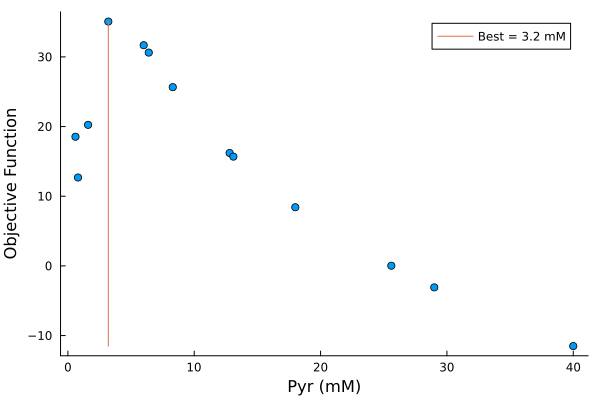

In [7]:
bstIn = findfirst(objs .== maximum(objs))

scatter(pyrs, objs, label = "", grid = false, ylabel = "Objective Function", xlabel = "Pyr (mM)")
plot!([pyrs[bstIn], pyrs[bstIn]], [minimum(objs), objs[bstIn]], label = "Best = "*string(pyrs[bstIn])*" mM")

# Extract Experimental Data

In [8]:
pyrs[bstIn]

3.2

In [9]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_0-6mMPyr_Dat.csv", mainpath*"3Mil_1-6mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv", 
         mainpath*"3Mil_"*replace(string(pyrs[bstIn]), "." => "-", count = 1)*"mMPyr_Dat.csv"];
conce = [0.6, 1.6, 12.8, pyrs[bstIn]];


Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat_Scal(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])

Dict{String, Any} with 16 entries:
  "Means"  => [1226.15 4528.94 32574.2 9177.49; 723.012 3020.78 23317.9 6162.55…
  "stsl"   => [77 77 77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0 0 0; 20 20 20 20; … ; 390 390 390 390; 395 395 395 395]
  "obser"  => 2
  "Y0us"   => [600.0 1600.0 12800.0 3200.0; 0.0 0.0 0.0 0.0; … ; 0.0 0.0 0.0 0.…
  "ts"     => [1.0e-20 1.0e-20 1.0e-20 1.0e-20; 1.0 1.0 1.0 1.0; … ; 394.0 394.…
  "itp"    => [0.0, 0.0, 0.0, 0.0]
  "ScFms"  => [17.0298 23.5882 21.2072 23.8997]
  "ncells" => [3 3 3 3]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [81.2187 672.75 1846.98 821.947; 72.3012 445.178 1039.87 491.932;…
  "m"      => 4
  "nmCls"  => [3.0e6 3.0e6 3.0e6 3.0e6]
  "nts"    => [395 395 395 395]

# Simulate Experiment Prior Prediction
CAREFUL!!! Simulations take a minute or more if you take all the samples!

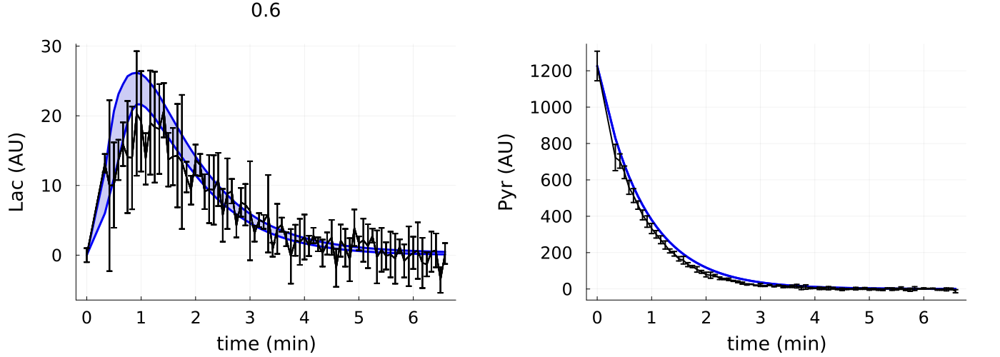

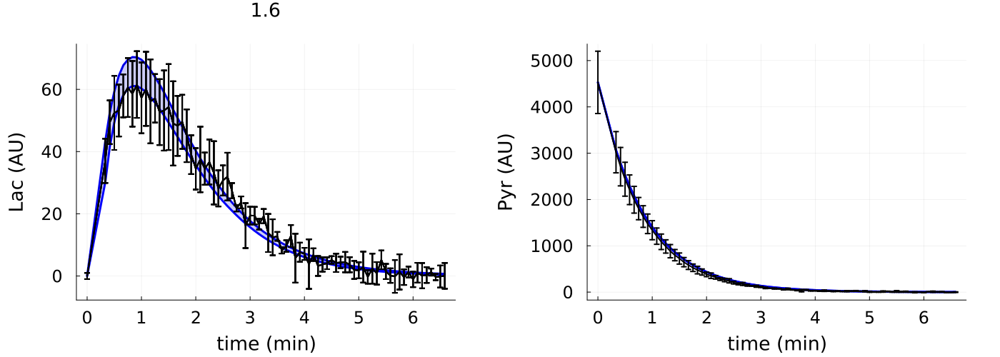

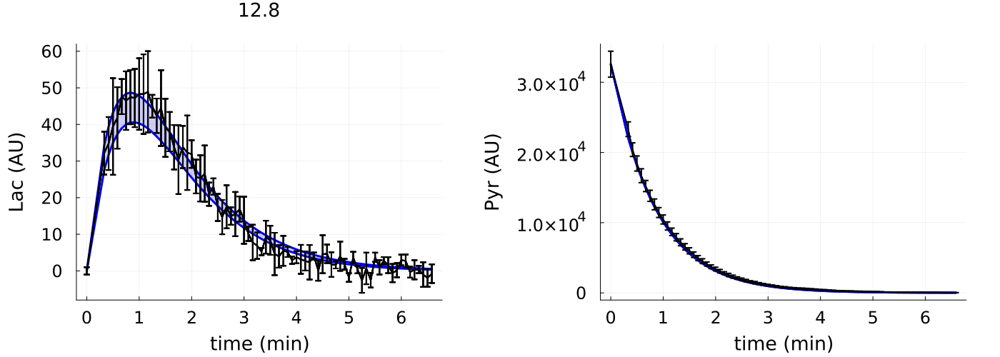

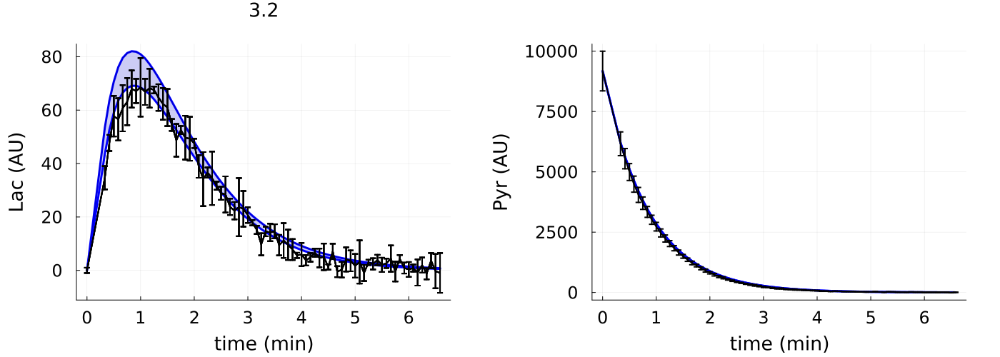

In [10]:
simPriorPredictAll(2000, dat, priorInfer[:,1:14], priorInfer[:,15:end], conce)

# MLE to obtain a good first guess for inference

In [11]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 3e6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE2(p)

1.2547543474131232e16

In [12]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE2; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:13], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*20, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.51 secs, 20 evals, 10 steps, improv/step: 0.400 (last = 0.4000), fitness=4648.372657903
1.03 secs, 30 evals, 16 steps, improv/step: 0.438 (last = 0.5000), fitness=4648.372657903
1.57 secs, 52 evals, 27 steps, improv/step: 0.444 (last = 0.4545), fitness=4648.372657903
2.15 secs, 64 evals, 33 steps, improv/step: 0.455 (last = 0.5000), fitness=4179.548019514
2.66 secs, 84 evals, 45 steps, improv/step: 0.489 (last = 0.5833), fitness=4179.548019514
3.18 secs, 103 evals, 57 steps, improv/step: 0.474 (last = 0.4167), fitness=4179.548019514
3.71 secs, 132 evals, 77 steps, improv/step: 0.481 (last = 0.5000), fitness=4179.548019514
4.21 secs, 153 evals, 91 steps, improv/step: 0.462 (last = 0.3571), fitness=4179.548019514
4.72 secs, 180 evals, 111 steps, improv/step: 0.459 (last = 0.4500), fitn

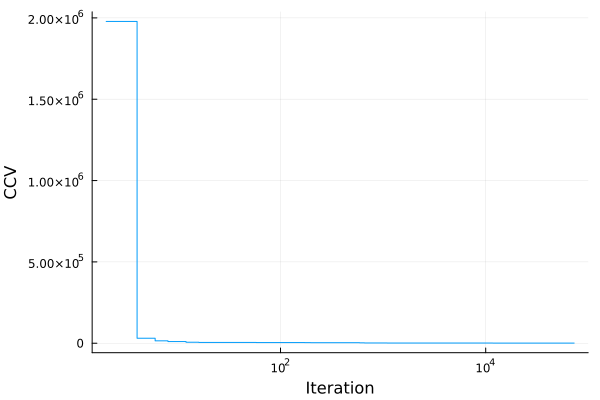

┌ Warning: Attempting to store var"#107#108".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [13]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

# Extract Parameter Vector
parfitT = zeros(16, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind];

# Save Data
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMTRRCmp_Exper_Iter4b.jld2", "FitsT",FitsT)
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter4b.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

In [14]:
# Load Data
ppT = JLD2.load("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter4b.jld2")["resMMat"][:,1]

16-element Vector{Float64}:
   51.73603062909275
   51.23
    3.481404559510676e-5
    0.020580715760993414
    8.846612602593271e-8
    0.15042923233501998
    1.9999986753983159
    0.20287130706086992
    3.300773776636617e-8
    7.719441406447494e-6
    1.999997349458333
    1.210785696033553e-7
    3.0e6
  106.83220286662319
 6081.46774769785
    1.167997258919411

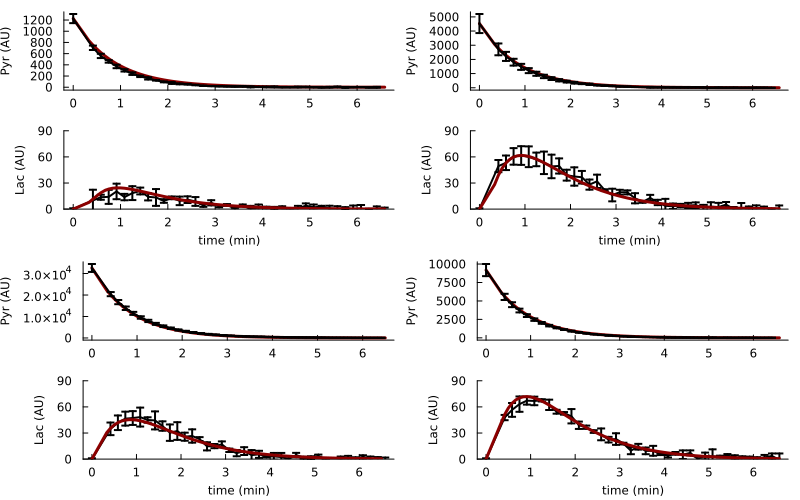

In [15]:
pst = Array{Any}(undef, length(conce))
i = 1
for i in 1:length(conce)
     tsC2 = dat["sts"][:,i];
     if i == 3
          tsC2 = dat["sts"][1:end-1,3];
     end
     ts = 0:tsC2[end];
     ivss = [round(conce[i], digits = 1)*1000, 0, 0, ppT[14], ppT[15], ppT[16], 0, 0, 0, 0, 0, round(conce[i], digits = 1)*1000, 0, round(conce[i], digits = 1)*1000*(dat["ScFms"][i]*0.12)];;
     samps = convert.(Int, tsC2);

     SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(ppT[1:13], dat["ScFms"][i], 0), ivss, samps);

     pps = plot(dat["sts"][1:2:end,i]./60, dat["Means"][1:2:end,i,2], yerror = dat["Erros"][1:2:end,i,2], linewidth = 2, colour = "black", label = "",
               margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18),
               xlabel = "time (min)", ylabel = "Lac (AU)", size = (800,500))

          plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4", label = "", grid = false, ylim=(0,90))


     ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4", label = "", grid = false,
          margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18))
     plot!(dat["sts"][1:2:end-1,i]./60, dat["Means"][1:2:end-1,i,1], yerror = dat["Erros"][1:2:end-1,i,1], linewidth = 2, colour = "black", label = "", ylabel = "Pyr (AU)")

     pst[i] = plot(ps, pps, layout=(2,1))
end

plot(pst...)

## Compute structure for Stan's initial guess

In [18]:
jj = vcat(1, 3:12)

preTrans = zeros(14);

for i in 1:length(jj)
    
    if i == 1
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].μ)/priorTheta[jj[i]].σ;
    else
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].untruncated.μ)/priorTheta[jj[i]].untruncated.σ;
    end
    
end
kk = [14,15,16]
for i in 1:length(priotY0)
    preTrans[i+11] = (ppT[kk[i]]-priotY0[i].untruncated.μ)/priotY0[i].untruncated.σ;
end


samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict2(repeat(preTrans, 1, 10), names)

ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 1.57315
  "LDH"  => 4.00672
  "kin"  => -0.986074
  "ki"   => 1.10526
  "kunE" => -1.0
  "kpl"  => -0.25161
  "NADH" => -1.47129
  "kup"  => -0.786451
  "T1_X" => 1.0816
  "kbp"  => 1.10526
  "kr"   => -0.999865
  "NAD"  => 2.31139
  "kun"  => 0.00286155
  "kbn"  => -0.823068

# Inference

In [20]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\HP_PyrLac_CmpRepresMo_Scallable2.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Iter4b_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.9;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=11;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

# StanModel = Stanmodel(name="PyrCompRepr_Iter2_Try1", model=Model, nchains =10,
#             num_samples  = 800, num_warmup = 400, printsummary=true);
# StanModel.method.save_warmup = true;
# StanModel.method.adapt.delta = 0.90;
# StanModel.method.algorithm.stepsize = 0.1;
# StanModel.method.algorithm.engine.max_depth=10;
# StanModel.method.algorithm.stepsize_jitter = 0.5;

11

In [21]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Iter4b_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(200,200,200,200,200,200,200,200,200,200); thin=(1,1,1,1,1,1,1,1,1,1); 10000 iterations saved.

Warmup took (45955, 47573, 40128, 43688, 38100, 38758, 47379, 45835, 44448, 47159) seconds, 122 hours total
Sampling took (193647, 180007, 114742, 157589, 123929, 118329, 147687, 243139, 186517, 138202) seconds, 445 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -8.3e+02  6.1e-02  3.0e+00  -8.3e+02  -8.3e+02  -8.2e+02  2.4e+03  1.5e-03  1.0e+00
accept_stat__    9.6e-01  3.5e-03  6.7e-02   8.2e-01   9.8e-01   1.0e+00  3.7e+02  2.3e-04  1.0e+00
stepsize__       6.8e-03  8.3e-04  1.9e-03   3.9e-03   7.0e-03   1.0e-02  5.0e+00  3.1e-06  8.3e+13
treedepth__      9.1e+00  1.7e-01  6.8e-01   8.0e+00   9.0e+00   1.0e+01  1.5e+01  9.6e-06  1.2e+00
n_leapfrog__     7.5e+02  8.5e+01  3.5e+02

(0, [-837.391 0.88044 … 5513.02 1.26047; -837.391 0.0 … 5513.02 1.26047; … ; -830.734 0.993664 … 4121.91 0.715794; -833.093 0.951018 … 5000.03 1.1339;;; -849.675 0.923521 … 5335.96 0.885548; -849.675 0.0 … 5335.96 0.885548; … ; -826.807 0.95864 … 2035.89 1.04649; -827.524 0.991138 … 2663.41 1.10701;;; -846.621 0.000608774 … 6081.47 1.1692; -846.621 0.0 … 6081.47 1.1692; … ; -827.477 0.979409 … 1874.32 0.772081; -827.112 0.99641 … 6655.38 0.879097;;; -844.341 0.99807 … 3297.82 0.810777; -844.341 0.0 … 3297.82 0.810777; … ; -829.568 0.992456 … 3785.86 0.979842; -833.898 0.998526 … 4593.48 1.03341;;; -841.325 0.722146 … 5121.12 0.820442; -841.325 0.0 … 5121.12 0.820442; … ; -828.394 0.970607 … 3186.8 0.991989; -828.071 0.944989 … 4222.84 0.810619;;; -846.83 0.99828 … 4034.39 0.710675; -846.83 0.0 … 4034.39 0.710675; … ; -826.417 0.99898 … 4183.5 1.16233; -829.169 0.986985 … 4739.9 0.772524;;; -844.163 0.999879 … 3983.79 0.67363; -844.163 0.0 … 3983.79 0.67363; … ; -831.008 0.72293 … 4637.

In [24]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PyrCompetitiveRepressionInferExpScal_Iter4b_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-16:end, 1], chns[201:end, end-16:end, 2], chns[201:end, end-16:end, 3], chns[201:end, end-16:end, 4], chns[201:end, end-16:end, 5], 
              chns[201:end, end-16:end, 6], chns[201:end, end-16:end, 7], chns[201:end, end-16:end, 8], chns[201:end, end-16:end, 9], chns[201:end, end-16:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4b_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4b_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4b_Try1.csv"

In [25]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4b_Try1.csv", DataFrame))

8000×17 Matrix{Float64}:
 52.8488  51.23  4.29785e-5  …  23.8997  412.313  4135.07  0.918253
 51.0524  51.23  4.06198e-5     23.8997  123.041  2774.46  1.0624
 50.6975  51.23  3.57084e-5     23.8997  155.783  4048.41  1.11098
 51.554   51.23  3.88936e-5     23.8997  245.464  4882.04  1.07187
 49.4043  51.23  3.91193e-5     23.8997  356.552  4350.0   0.95822
 49.8056  51.23  4.26039e-5  …  23.8997  250.155  4284.28  1.04009
 50.1062  51.23  5.09687e-5     23.8997  114.342  2957.55  0.995706
 51.8466  51.23  4.79198e-5     23.8997  450.694  4669.7   0.864846
 50.5145  51.23  4.67525e-5     23.8997  202.802  5325.94  0.988179
 47.8616  51.23  4.06223e-5     23.8997  407.471  4618.93  0.988121
  ⋮                          ⋱                       ⋮     
 54.6092  51.23  5.26296e-5     23.8997  253.241  2920.01  0.906692
 52.535   51.23  4.13805e-5     23.8997  445.232  5311.88  0.870816
 50.2419  51.23  3.91277e-5     23.8997  390.602  4035.05  1.03311
 53.0602  51.23  3.98335e-5     23.899

# Plot Posterior VS Prior

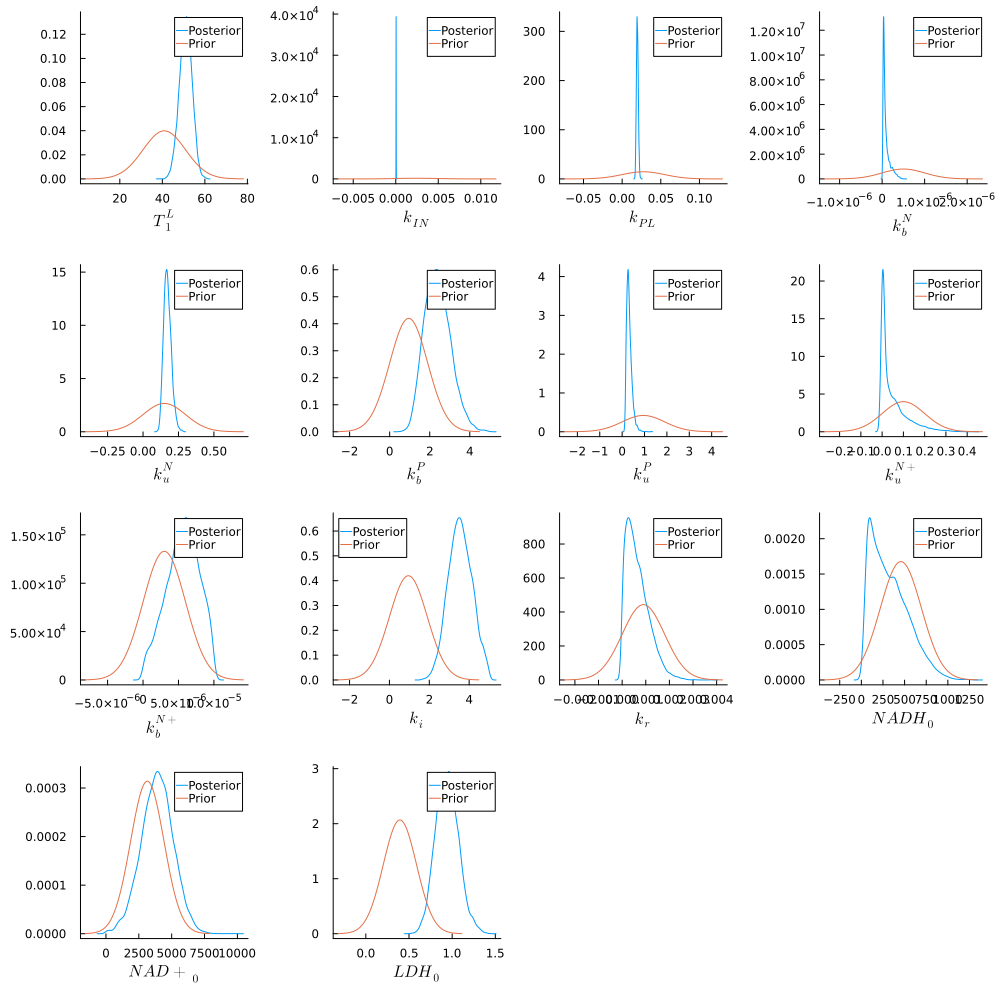

In [26]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    pltsPost[i] = plot(kde(poster[:,indss[i]]), label = "Posterior", xlabel = namess[i])
    try
        plot!(prisDis[indss[i]].untruncated, label = "Prior")
    catch
        plot!(prisDis[indss[i]], label = "Prior")
    end

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [27]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,15:end]))))

113.6572105015332

In [28]:
[mode(poster[poster[:,11] .> 2, i]) for i in 1:17]

17-element Vector{Float64}:
   51.3901
   51.23
    4.61499e-5
    0.0186079
    2.29845e-8
    0.155823
    1.86966
    0.360253
    0.11272
    3.17232e-6
    3.48524
    0.00111361
    3.0e6
   23.8997
  405.763
 2383.32
    0.864001

In [65]:
using CairoMakie
using PairPlots
using DataFrames

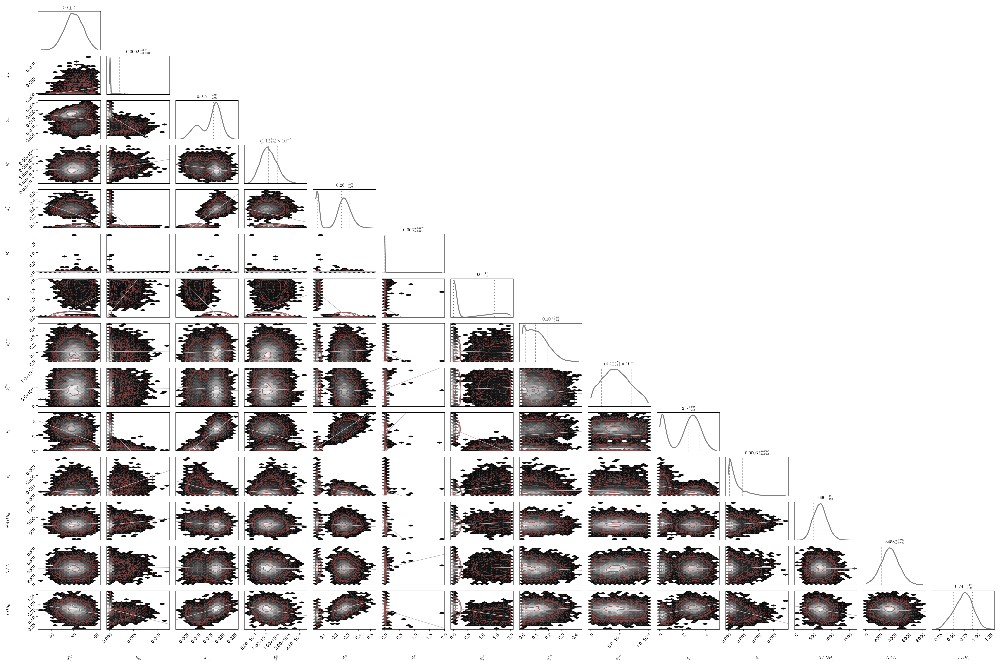

In [66]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,15:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

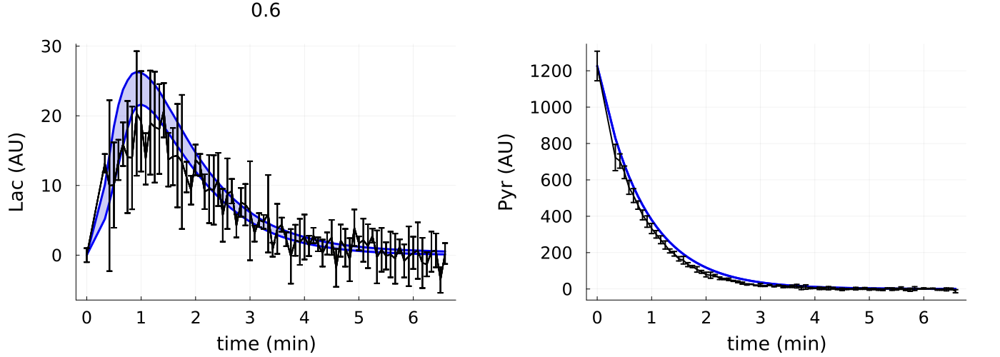

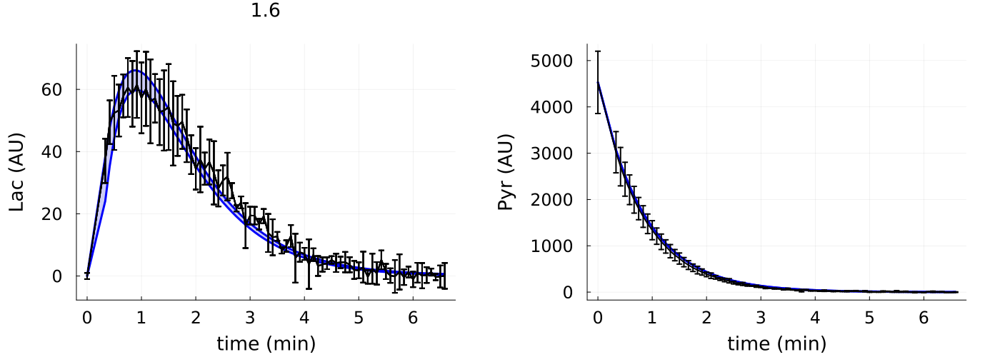

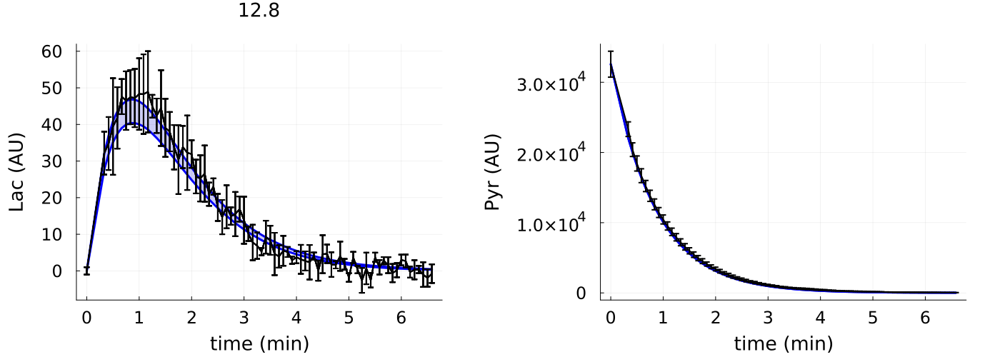

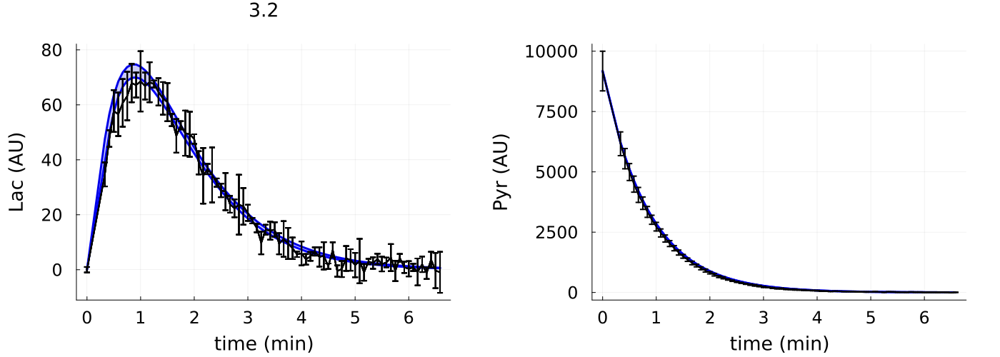

In [29]:
simPriorPredictAll(2000, dat, poster[:,1:14], poster[:,15:end], conce)